In [1]:
# conda env 'vis2'

import sys
import os
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

from util import load_sensor_dict
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import glob
import at3d

from collections import defaultdict

In [2]:
def load_retreival(dir):
    assert os.path.isdir(dir + '/iterations/')
    name = os.path.split(dir)[-1]
    files = np.sort(glob.glob(dir + '/iterations/iter*.nc'))
    sensors, solvers, rte_grid = at3d.util.load_forward_model(files[-1])
    data = {
        'files': files,
        'sensors': sensors,
        'solvers': solvers,
        'rte_grid': rte_grid
    }
    return data

In [4]:
def traverse(dir, data, parent_key=()):
    name = os.path.split(dir)[-1]
    parent_key += (name,)
    if(os.path.isdir(dir + '/iterations/')):
        data[parent_key] = load_retreival(dir)
    else:
        for n in os.listdir(dir):
            traverse(dir+'/'+n, data, parent_key)


In [5]:
version_dir = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V00'
data = defaultdict(defaultdict)
traverse(version_dir, data)

/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '61'. Max cell optical depth: '3.3198599815368652'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2_clone/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/env

In [6]:
# def print_nested_dictionary_keys(nested_dict, indent=0):
#     """
#     Recursively prints keys from a nested dictionary with indentation.

#     Args:
#         nested_dict (dict): The nested dictionary to print keys from.
#         indent (int): The current indentation level.
#     """
#     for key, value in nested_dict.items():
#         print('  ' * indent + str(key)) # Print key with indentation
#         if isinstance(value, dict):
#             print_nested_dictionary_keys(value, indent + 1) # Recursive call for nested dictionaries

# print_nested_dictionary_keys(data)

### Error Metrics

$\bm{\beta_p}$ is the perturbed extinction coefficient vector. $\bm{\beta_r}$ is the reference extinction coefficient vector.

Relative Bias (Jesse's relative bias):

$\text{Relative Bias} = 100 \times \frac{||\bm{\beta_p}||_1 - ||\bm{\beta_r}||_1}{||\bm{\beta_r}||_1}$

Relative Difference (Jesse's relative RMSE):

$\text{Relative Difference} = 100 \times \frac{||\bm{\beta_p} - \bm{\beta_r}||_2}{||\bm{\beta_r}||_2}$

$||\bm{x}||_1 = \sum_i |x_i|$ and $||\bm{x}||_2 = \left(\sum_i x_i^2\right)^{\frac{1}{2}}$

Mean Absolute Error:

$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |\beta_{p,i} - \beta_{r, i}|$

Root Mean Square Error:

$\text{RMSE} = \left(\frac{1}{n} \sum_{i=1}^n \left(\beta_{p,i} - \beta_{r,i}\right)^2\right)^\frac{1}{2} = \left(\frac{1}{n} ||\bm{\beta_p} - \bm{\beta_r}||_2^2\right)^{\frac{1}{2}}$

Correlation Coefficient (Pearson's r):

$r = \frac{\sum_i (\beta_{p,i} - \bar{\bm{\beta_p}})(\beta_{r,i} - \bar{\bm{\beta_r}})}{\sqrt{\sum_i (\beta_{p,i} - \bar{\bm{\beta_p}})^2} \sqrt{\sum_i (\beta_{r,i} - \bar{\bm{\beta_r}})^2}}$

Normalized Mean Bias (NMB):

$\text{NMB} = \frac{\sum_i (\beta_{p,i} - \beta_{r,i})}{\sum_i \beta_{r,i}}$


In [21]:
def calc_error_metrics(reference, data):
    if('solvers' in list(data.keys())):
        ext_tmp = np.ravel(data['solvers'][0.67].medium['cloud'].extinction.data)
        ext_ref = np.ravel(reference['solvers'][0.67].medium['cloud'].extinction.data)
        data['relative difference'] = 100 * (np.sum((ext_tmp - ext_ref)**2))**0.5 / (np.sum(ext_ref)**2)**0.5
        data['relative bias'] = 100 * (np.sum(np.abs(ext_tmp)) - np.sum(np.abs(ext_ref))) / (np.sum(np.abs(ext_ref)))
        data['MAE'] = np.sum(np.abs(ext_tmp - ext_ref)) / len(ext_tmp)
        data['RMSE'] = (np.sum((ext_tmp - ext_ref)**2) / len(ext_tmp))**0.5
        data['r'] = (np.sum((ext_tmp - np.mean(ext_tmp)) * (ext_ref - np.mean(ext_ref)))) / ((np.sum((ext_tmp - np.mean(ext_tmp))**2)**0.5) * (np.sum((ext_ref - np.mean(ext_ref))**2)**0.5))
        data['NMB'] = np.sum(ext_tmp - ext_ref) / np.sum(ext_ref)

        tmp = data['solvers'][0.67].medium['cloud'].copy(deep=True)
        mask = tmp.extinction.data > 0
        tmp['cvm'] = (['x', 'y', 'z'], mask)
        cv = tmp.cvm.integrate(['x','y','z']).data
        tmp_ref = reference['solvers'][0.67].medium['cloud'].copy(deep=True)
        mask = tmp_ref.extinction.data > 0
        tmp_ref['cvm'] = (['x', 'y', 'z'], mask)
        cv_ref = tmp_ref.cvm.integrate(['x','y','z']).data
        data['cloud volume'] = cv
        data['delta volume'] = cv - cv_ref
    else:
        for n in data:
            calc_error_metrics(reference, data[n])

In [22]:
reference = data[('V00', 'default')]
calc_error_metrics(reference, data)

In [24]:
CVM_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/CVM_default.nc'
cvm = xr.load_dataset(CVM_file)
vol_cvm = cvm.cloud_volume_mask.integrate(['x','y','z']).data
print('CVM Volume: {:.3f} km**3'.format(vol_cvm))

CVM Volume: 41.659 km**3


In [27]:
print('{:<28} | {:<19} | {:<23} | {:<20} | {:<20}'.format('Path', 'Relative Bias (%)', 'Relative Difference (%)', 'Cloud Volume (km**3)', 'Change in Volume (km**3)'))
print('-'*125)
for k, v in data.items():
    print('{:<28} | {:<19} | {:<23} | {:<20} | {:<20}'.format(str(k), v['relative bias'], v['relative difference'], v['cloud volume'], v['delta volume']))

Path                         | Relative Bias (%)   | Relative Difference (%) | Cloud Volume (km**3) | Change in Volume (km**3)
-----------------------------------------------------------------------------------------------------------------------------
('V00', 'default')           | 0.0                 | 0.0                     | 23.637160937500003   | 0.0                 
('V00', 'HBC', 'periodic')   | -33.065360498567    | 1.4872571612945487      | 23.967642187500005   | 0.33048125000000184 
('V00', 'CVM', 'noCVM')      | 25.93012704118924   | 1.972212749430089       | 61.7173734375        | 38.0802125          
('V00', 'aerosol', 'mix22')  | -1.4366843166154488 | 0.6694273416749987      | 27.6929296875        | 4.055768749999999   
('V00', 'aerosol', 'mix54')  | -5.635939133955863  | 0.4306256681627287      | 21.859784375000007   | -1.7773765624999953 
('V00', 'aerosol', '0p150')  | 22.54135352977552   | 0.5244005099883929      | 33.205425000000005   | 9.568264062500003   
('V00', '

### Fourier Analysis

In [67]:
def f(t, freq=1, phi=0):
    return np.cos(2*np.pi*freq*t + phi)

<StemContainer object of 3 artists>

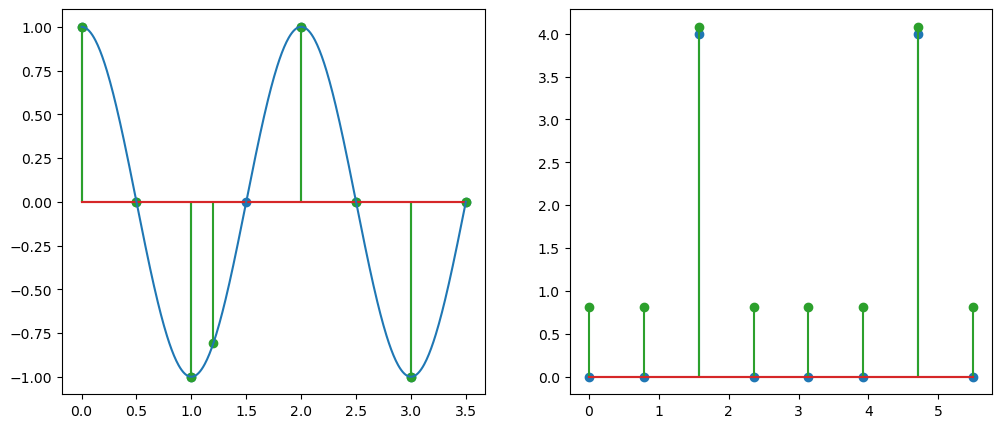

In [104]:
freq = 0.5
phi = 0
# t = np.arange(0, 4.0, 0.5)
t1 = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5])
t2 = np.array([0, 0.5, 1, 1.2, 2, 2.5, 3, 3.5])
x1 = f(t1, freq=freq, phi=phi)
x2 = f(t2, freq=freq, phi=phi)
thr = np.linspace(np.min(t), np.max(t), 500)
xhr = f(thr, freq=freq, phi=phi)

N1 = len(x1)
k1 = np.arange(N1)
omega_k1 = (2*np.pi*k1) / N1
X1 = np.zeros(N1, dtype=complex)
for ki in k1:
    for n in range(N1):
        X1[ki] += x1[n] * np.exp(-1j*2*np.pi*ki*n / N1)

N2 = len(x2)
k2 = np.arange(N2)
omega_k2 = (2*np.pi*k2) / N2
X2 = np.zeros(N2, dtype=complex)
for ki in k2:
    for n in range(N2):
        X2[ki] += x2[n] * np.exp(-1j*2*np.pi*ki*n / N2)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].stem(t1, x1, 'tab:blue')
ax[0].stem(t2, x2, 'tab:green')
ax[0].plot(thr, xhr)
ax[1].stem(omega_k1, np.abs(X1), 'tab:blue')
ax[1].stem(omega_k2, np.abs(X2), 'tab:green')